# JS06 (Regresi) - Praktikum 1: Regresi Linier
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Penerapan Simple Linear Regression pada dataset `dataset.csv` (Ecommerce Customers) untuk memprediksi `Yearly Amount Spent` dari `Length of Membership`, disertai analisis korelasi heatmap, residual error terms, dan evaluasi $R^2$.


5 Data Teratas:
                           Email                                                       Address            Avatar  Avg. Session Length  Time on App  Time on Website  Length of Membership  Yearly Amount Spent
0      mstephenson@fernandez.com                835 Frank Tunnel\r\nWrightmouth, MI 82180-9605            Violet            34.497268    12.655651        39.577668              4.082621           587.951054
1              hduke@hotmail.com              4547 Archer Common\r\nDiazchester, CA 06566-8576         DarkGreen            31.926272    11.109461        37.268959              2.664034           392.204933
2               pallen@yahoo.com  24645 Valerie Unions Suite 582\r\nCobbborough, DC 99414-7564            Bisque            33.000915    11.330278        37.110597              4.104543           487.547505
3        riverarebecca@gmail.com            1414 David Throughway\r\nPort Jason, OH 22070-1220       SaddleBrown            34.305557    13.717514        36

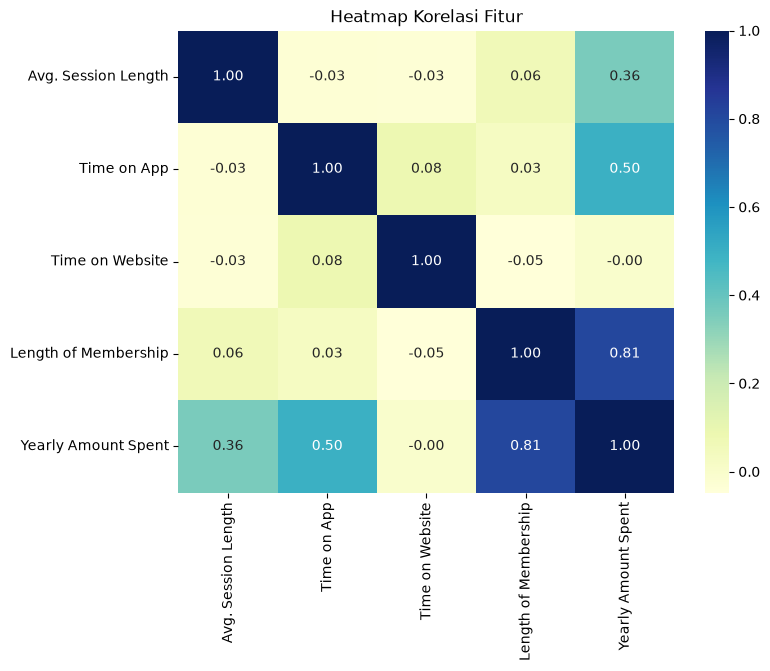

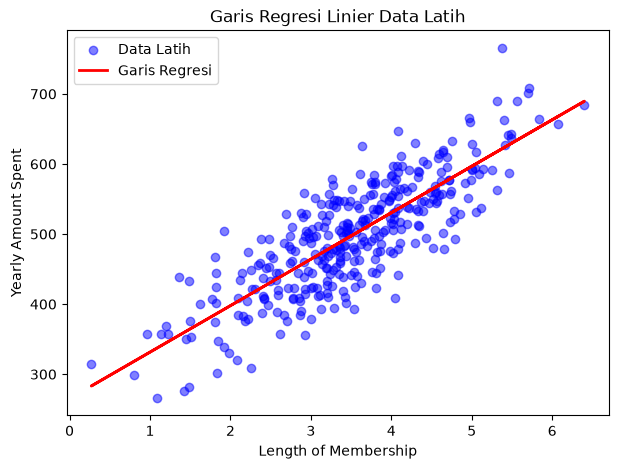

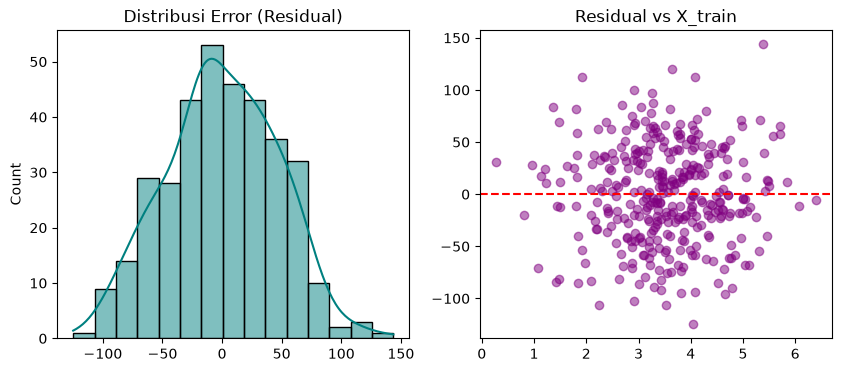

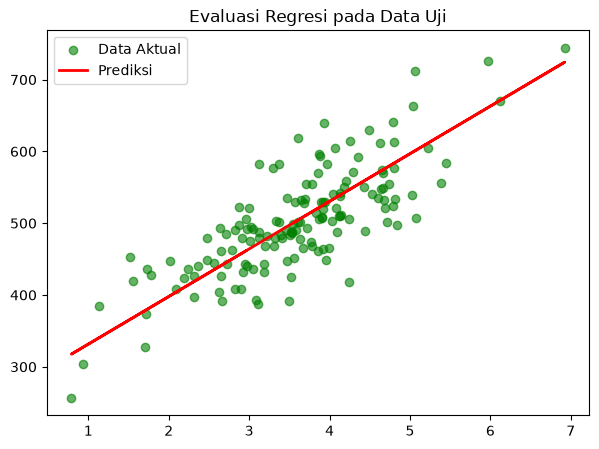

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# 1. Baca Data
data = pd.read_csv('dataset.csv')
print("5 Data Teratas:")
display(data.head())
print(f"Bentuk data: {data.shape}")

# 2. Visualisasi Heatmap Korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(data.select_dtypes(include=[np.number]).corr(), cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Heatmap Korelasi Fitur")
plt.show()

# 3. Pemisahan Variabel X dan y
X = data['Length of Membership']
y = data['Yearly Amount Spent']

# 4. Split 70:30
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

# 5. Training OLS
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()
print(lr.summary())

# Visualisasi Garis Regresi
plt.figure(figsize=(7, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Data Latih')
plt.plot(X_train, lr.params.iloc[0] + lr.params.iloc[1] * X_train, 'r-', lw=2, label='Garis Regresi')
plt.title("Garis Regresi Linier Data Latih")
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.legend()
plt.show()

# 6. Analisis Residual
y_train_pred = lr.predict(X_train_sm)
res = y_train - y_train_pred

fig = plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(res, kde=True, bins=15, color='teal')
plt.title('Distribusi Error (Residual)')
plt.subplot(1, 2, 2)
plt.scatter(X_train, res, color='purple', alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual vs X_train')
plt.show()

# 7. Evaluasi pada Data Uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)
r2 = r2_score(y_test, y_test_pred)
print(f"R-squared pada Data Uji: {r2:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color='green', alpha=0.6, label='Data Aktual')
plt.plot(X_test, y_test_pred, 'r-', lw=2, label='Prediksi')
plt.title("Evaluasi Regresi pada Data Uji")
plt.legend()
plt.show()
